# CA3

# Amin Aghakasiri - 810101381

### SCM Implementation

In [17]:
import copy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [3]:
class SCM:
    def __init__(self):
        self.variables = {}

    def add_variable(self, name, parents, equation):
        if name in self.variables:
            raise ValueError(f"Variable '{name}' already exists.")

        for parent in parents:
            if parent not in self.variables:
                raise ValueError(
                    f"Parent '{parent}' has not been added yet. "
                    f"Add parent variables before adding '{name}'."
                )

        self.variables[name] = {
            "parents": list(parents),
            "equation": equation
        }

    def _build_graph(self):
        graph = nx.DiGraph()
        for var in self.variables:
            graph.add_node(var)

        for var, info in self.variables.items():
            for parent in info["parents"]:
                graph.add_edge(parent, var)

        return graph

    def sample(self, n_samples, seed=None):
        graph = self._build_graph()

        if not nx.is_directed_acyclic_graph(graph):
            raise ValueError("The graph must be a DAG.")

        causal_order = list(nx.topological_sort(graph))
        rng = np.random.default_rng(seed)
        samples = []
        for _ in range(n_samples):
            values = {}
            for var in causal_order:
                equation = self.variables[var]["equation"]
                values[var] = equation(values, rng)

            samples.append(values)

        return pd.DataFrame(samples)[causal_order]

    def do_operator(self, interventions):
        new_scm = copy.deepcopy(self)

        for var, fixed_value in interventions.items():
            if var not in new_scm.variables:
                raise ValueError(f"Variable '{var}' does not exist in the SCM.")

            def fixed_equation(values, rng, value=fixed_value):
                return value
            
            new_scm.variables[var]["parents"] = []
            new_scm.variables[var]["equation"] = fixed_equation

        return new_scm

    def plot_graph(self, title="SCM Graph"):
        graph = self._build_graph()

        if not nx.is_directed_acyclic_graph(graph):
            raise ValueError("The causal graph must be a DAG.")

        plt.figure(figsize=(7, 5))
        pos = nx.spring_layout(graph, seed=42)
        nx.draw(
            graph,
            pos,
            with_labels=True,
            node_size=2500,
            node_color="lightblue",
            font_size=12,
            font_weight="bold",
            arrows=True,
            arrowsize=20
        )
        plt.title(title)
        plt.show()

### Course Effect

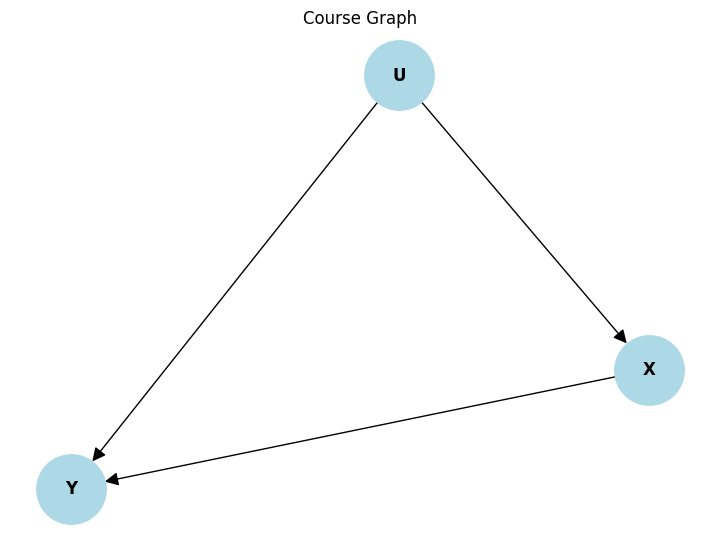

In [25]:
course_scm = SCM()
course_scm.add_variable(
    name="U",
    parents=[],
    equation=lambda values, rng: rng.normal(0, 1)
)

course_scm.add_variable(
    name="X",
    parents=["U"],
    equation=lambda values, rng: int(7 * values["U"] + rng.normal(0, 1) > 0)
)

course_scm.add_variable(
    name="Y",
    parents=["X", "U"],
    equation=lambda values, rng: 3 * values["X"] + 2 * values["U"] + rng.normal(0, 1)
)
course_scm.plot_graph("Course Graph")

In [6]:
observational_data = course_scm.sample(n_samples=10000, seed=42)
mean_y_x1 = observational_data.loc[observational_data["X"] == 1, "Y"].mean()
mean_y_x0 = observational_data.loc[observational_data["X"] == 0, "Y"].mean()
observational_difference = mean_y_x1 - mean_y_x0
print("E[Y | X = 1] =", mean_y_x1)
print("E[Y | X = 0] =", mean_y_x0)
print("Observational difference =", observational_difference)

E[Y | X = 1] = 4.608161807852955
E[Y | X = 0] = -1.6029061943711729
Observational difference = 6.211068002224128


In [8]:
scm_do_x1 = course_scm.do_operator({"X": 1})
data_do_x1 = scm_do_x1.sample(n_samples=10000, seed=42)
scm_do_x0 = course_scm.do_operator({"X": 0})
data_do_x0 = scm_do_x0.sample(n_samples=10000, seed=42)
mean_y_do_x1 = data_do_x1["Y"].mean()
mean_y_do_x0 = data_do_x0["Y"].mean()
true_causal_effect = mean_y_do_x1 - mean_y_do_x0
print("E[Y | do(X = 1)] =", mean_y_do_x1)
print("E[Y | do(X = 0)] =", mean_y_do_x0)
print("True causal effect (ATE) =", true_causal_effect)

E[Y | do(X = 1)] = 3.0080638848294043
E[Y | do(X = 0)] = 0.008063884829404771
True causal effect (ATE) = 2.9999999999999996


### Don't Smoke

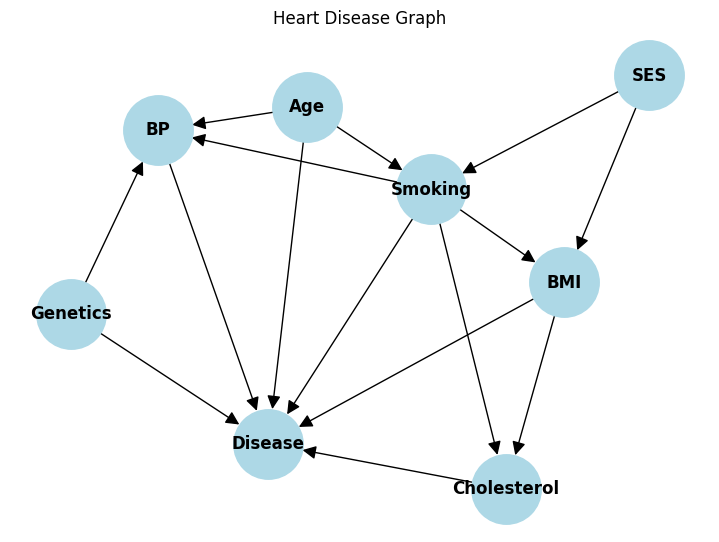

In [26]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

heart_scm = SCM()
heart_scm.add_variable(
    name="Age",
    parents=[],
    equation=lambda values, rng: rng.normal(50, 10)
)

heart_scm.add_variable(
    name="SES",
    parents=[],
    equation=lambda values, rng: rng.normal(0, 1)
)

heart_scm.add_variable(
    name="Genetics",
    parents=[],
    equation=lambda values, rng: rng.normal(0, 1)
)

heart_scm.add_variable(
    name="Smoking",
    parents=["Age", "SES"],
    equation=lambda values, rng: int(
        rng.uniform(0, 1) < sigmoid(-2 + 0.03 * values["Age"] - 0.5 * values["SES"])
    )
)

heart_scm.add_variable(
    name="BMI",
    parents=["Smoking", "SES"],
    equation=lambda values, rng: 25 + 2 * values["Smoking"] - values["SES"] + rng.normal(0, 3)
)

heart_scm.add_variable(
    name="BP",
    parents=["Smoking", "Age", "Genetics"],
    equation=lambda values, rng: (120 + 5 * values["Smoking"] + 0.3 * values["Age"] + 2 * values["Genetics"] + rng.normal(0, 10))
)

heart_scm.add_variable(
    name="Cholesterol",
    parents=["Smoking", "BMI"],
    equation=lambda values, rng: (180 + 10 * values["Smoking"] - 0.5 * values["BMI"] + rng.normal(0, 15))
)

heart_scm.add_variable(
    name="Disease",
    parents=["Smoking", "Age", "BMI", "BP", "Cholesterol", "Genetics"],
    equation=lambda values, rng: sigmoid(-15 + 0.6 * values["Smoking"] + 0.02 * values["Age"] + 0.01 * values["BMI"] + 0.03 * values["BP"] + 0.04 * values["Cholesterol"] + 0.2 * values["Genetics"])
)

heart_scm.plot_graph("Heart Disease Graph")

In [ ]:
def generate_exogenous_variables(n_samples=10000, seed=42):
    rng = np.random.default_rng(seed)
    exogenous = pd.DataFrame({
        "eps_Age": rng.normal(50, 10, n_samples),
        "eps_SES": rng.normal(0, 1, n_samples),
        "eps_Genetics": rng.normal(0, 1, n_samples),
        "eps_Smoke": rng.uniform(0, 1, n_samples),
        "eps_BMI": rng.normal(0, 3, n_samples),
        "eps_BP": rng.normal(0, 10, n_samples),
        "eps_Chol": rng.normal(0, 15, n_samples),
    })
    return exogenous


def apply_heart_scm(exogenous, smoking_intervention=None):
    df = pd.DataFrame(index=exogenous.index)
    df["Age"] = exogenous["eps_Age"]
    df["SES"] = exogenous["eps_SES"]
    df["Genetics"] = exogenous["eps_Genetics"]
    smoking_probability = sigmoid(
        -2 + 0.03 * df["Age"] - 0.5 * df["SES"]
    )

    if smoking_intervention is None:
        df["Smoking"] = (exogenous["eps_Smoke"] < smoking_probability).astype(int)
    else:
        df["Smoking"] = int(smoking_intervention)

    df["BMI"] = 25 + 2 * df["Smoking"] - df["SES"] + exogenous["eps_BMI"]
    df["BP"] = 120 + 5 * df["Smoking"] + 0.3 * df["Age"] + 2 * df["Genetics"] + exogenous["eps_BP"]
    df["Cholesterol"] = 180 + 10 * df["Smoking"]- 0.5 * df["BMI"] + exogenous["eps_Chol"]
    df["Disease"] = sigmoid(-15 + 0.6 * df["Smoking"] + 0.02 * df["Age"] + 0.01 * df["BMI"] + 0.03 * df["BP"] + 0.04 * df["Cholesterol"] + 0.2 * df["Genetics"])

    return df

exogenous = generate_exogenous_variables(n_samples=10000, seed=42)
observational_data = apply_heart_scm(exogenous, smoking_intervention=None)
# everyone smokes
data_do_smoking_1 = apply_heart_scm(exogenous, smoking_intervention=1)
# no one smokes
data_do_smoking_0 = apply_heart_scm(exogenous, smoking_intervention=0)

In [12]:
ate = data_do_smoking_1["Disease"].mean() - data_do_smoking_0["Disease"].mean()
print("E[Disease | do(Smoking = 1)] =", data_do_smoking_1["Disease"].mean())
print("E[Disease | do(Smoking = 0)] =", data_do_smoking_0["Disease"].mean())
print("ATE =", ate)

E[Disease | do(Smoking = 1)] = 0.15769007417519143
E[Disease | do(Smoking = 0)] = 0.06056391668442703
ATE = 0.09712615749076439


In [13]:
smokers_mask = observational_data["Smoking"] == 1
att = data_do_smoking_1.loc[smokers_mask, "Disease"].mean() - data_do_smoking_0.loc[smokers_mask, "Disease"].mean()
print("E[Disease_do(Smoking=1) | Smoking = 1] =", data_do_smoking_1.loc[smokers_mask, "Disease"].mean())
print("E[Disease_do(Smoking=0) | Smoking = 1] =", data_do_smoking_0.loc[smokers_mask, "Disease"].mean())
print("ATT =", att)

E[Disease_do(Smoking=1) | Smoking = 1] = 0.15973162282949827
E[Disease_do(Smoking=0) | Smoking = 1] = 0.06140465220350135
ATT = 0.0983269706259969


In [14]:
older_mask = observational_data["Age"] > 55
younger_mask = observational_data["Age"] <= 55
cate_older = data_do_smoking_1.loc[older_mask, "Disease"].mean() - data_do_smoking_0.loc[older_mask, "Disease"].mean()
cate_younger = data_do_smoking_1.loc[younger_mask, "Disease"].mean() - data_do_smoking_0.loc[younger_mask, "Disease"].mean()
print("CATE for Age > 55 =", cate_older)
print("CATE for Age <= 55 =", cate_younger)

CATE for Age > 55 = 0.12075676331390309
CATE for Age <= 55 = 0.08685345510280024


### Website

In [33]:
df = pd.read_csv("website_engagement_data.csv")
print("First rows:")
print(df.head())
print("\nColumns:")
print(df.columns)
print("\nMissing values:")
print(df.isna().sum())
df["new_layout"] = (df["layout"] == "New_Layout").astype(int)

First rows:
   user_id age_group      layout  time_spent
0     1001     Young  Old_Layout       13.68
1     1002     Older  New_Layout        6.76
2     1003     Older  Old_Layout        4.66
3     1004     Older  New_Layout        8.55
4     1005     Young  New_Layout       19.37

Columns:
Index(['user_id', 'age_group', 'layout', 'time_spent'], dtype='object')

Missing values:
user_id       0
age_group     0
layout        0
time_spent    0
dtype: int64


#### 1- Naive Model

In [41]:
print("Mean time_spent by layout:")
print(df.groupby("layout")["time_spent"].mean())
naive_model = smf.ols("time_spent ~ new_layout", data=df).fit()
print(naive_model.summary())
print("Naive model coefficient for New Layout:", naive_model.params["new_layout"])
print("Naive model p-value:", naive_model.pvalues["new_layout"])

Mean time_spent by layout:
layout
New_Layout     9.730547
Old_Layout    12.501732
Name: time_spent, dtype: float64
                            OLS Regression Results                            
Dep. Variable:             time_spent   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     101.7
Date:                Fri, 12 Jun 2026   Prob (F-statistic):           7.64e-23
Time:                        13:07:44   Log-Likelihood:                -2877.8
No. Observations:                1000   AIC:                             5760.
Df Residuals:                     998   BIC:                             5769.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------

#### 2- Visual Understanding

Age group by layout:
layout     New_Layout  Old_Layout
age_group                        
Older             471         108
Young              96         325


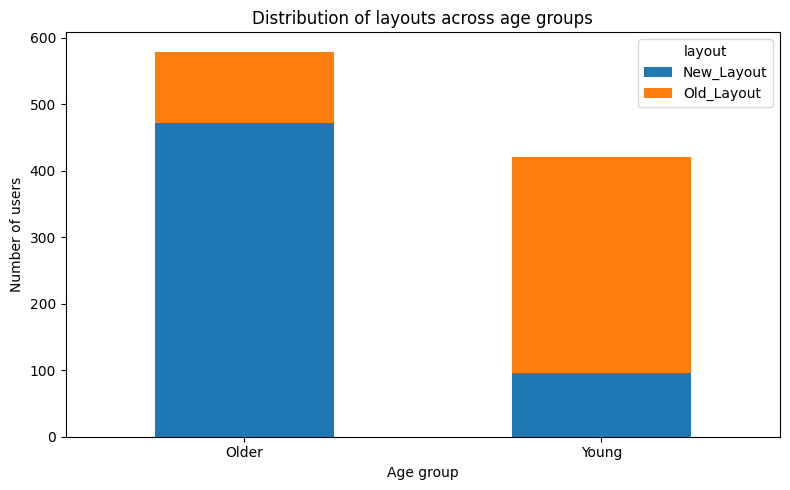

In [35]:
age_layout_table = pd.crosstab(df["age_group"], df["layout"])
print("Age group by layout:")
print(age_layout_table)
age_layout_table.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.xlabel("Age group")
plt.ylabel("Number of users")
plt.title("Distribution of layouts across age groups")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Mean time_spent by age_group and layout:
age_group  layout    
Older      New_Layout     8.035499
           Old_Layout     4.879815
Young      New_Layout    18.046875
           Old_Layout    15.034554
Name: time_spent, dtype: float64


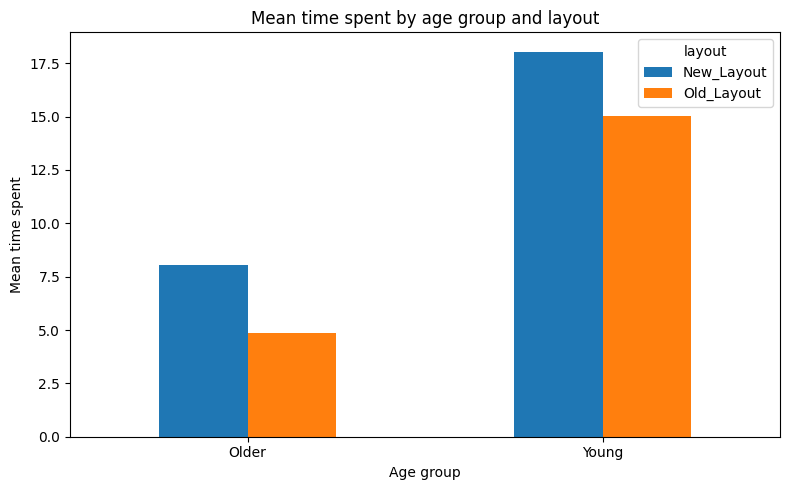

In [36]:
group_means = df.groupby(["age_group", "layout"])["time_spent"].mean()
print("Mean time_spent by age_group and layout:")
print(group_means)
pivot_means = group_means.unstack()
pivot_means.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Age group")
plt.ylabel("Mean time spent")
plt.title("Mean time spent by age group and layout")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

C:\Users\Amin\AppData\Local\Temp\ipykernel_23204\2999003606.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=labels)


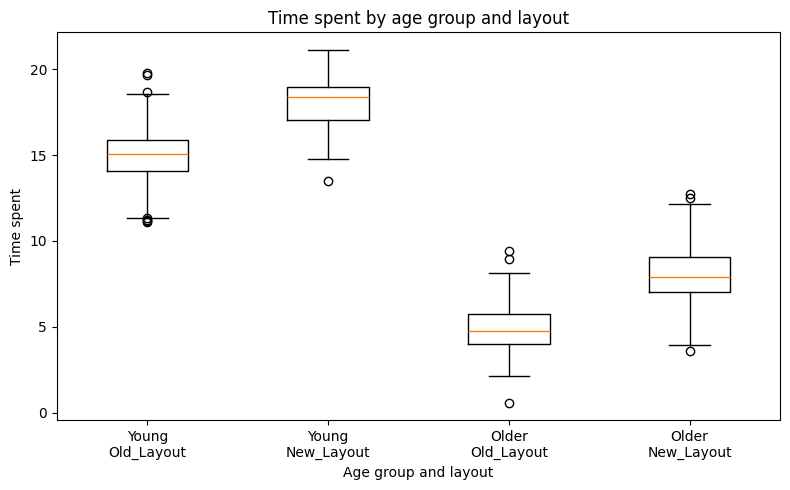

In [37]:
age_groups = ["Young", "Older"]
layouts = ["Old_Layout", "New_Layout"]
box_data = []
labels = []
for age in age_groups:
    for layout in layouts:
        values = df.loc[
            (df["age_group"] == age) & (df["layout"] == layout),
            "time_spent"
        ]
        box_data.append(values)
        labels.append(f"{age}\n{layout}")

plt.figure(figsize=(8, 5))
plt.boxplot(box_data, labels=labels)
plt.xlabel("Age group and layout")
plt.ylabel("Time spent")
plt.title("Time spent by age group and layout")
plt.tight_layout()
plt.show()

#### 3- SCM

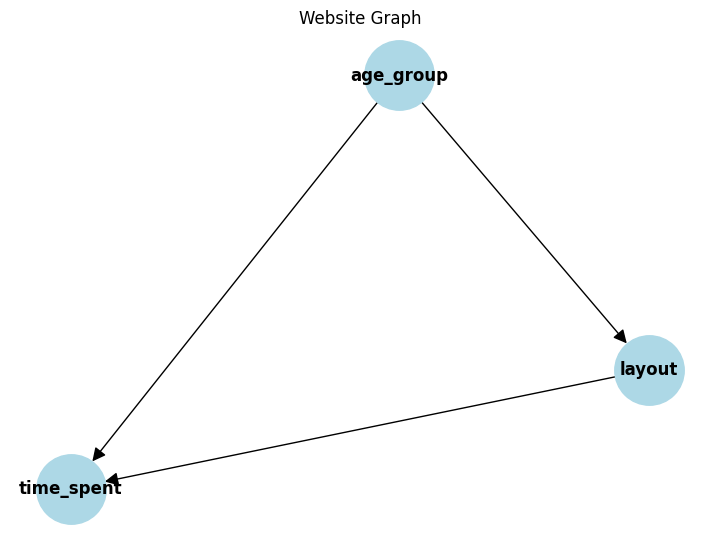

In [38]:
website_scm = SCM()
website_scm.add_variable(
    name="age_group",
    parents=[],
    equation=lambda values, rng: rng.choice(["Young", "Older"])
)

website_scm.add_variable(
    name="layout",
    parents=["age_group"],
    equation=lambda values, rng: rng.choice(["Old_Layout", "New_Layout"])
)

website_scm.add_variable(
    name="time_spent",
    parents=["layout", "age_group"],
    equation=lambda values, rng: rng.normal(0, 1)
)
website_scm.plot_graph("Website Graph")

In [42]:
adjusted_model = smf.ols("time_spent ~ new_layout + C(age_group)", data=df).fit()
print(adjusted_model.summary())
print("New coefficient for New Layout:", adjusted_model.params["new_layout"])
print("New p-value:", adjusted_model.pvalues["new_layout"])

                            OLS Regression Results                            
Dep. Variable:             time_spent   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     4231.
Date:                Fri, 12 Jun 2026   Prob (F-statistic):               0.00
Time:                        13:08:11   Log-Likelihood:                -1801.4
No. Observations:                1000   AIC:                             3609.
Df Residuals:                     997   BIC:                             3624.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 4.93

#### 4- Placebo Test

In [43]:
rng = np.random.default_rng(42)
df["placebo_layout"] = rng.permutation(df["new_layout"].values)
placebo_model = smf.ols("time_spent ~ placebo_layout + C(age_group)", data=df).fit()
print(placebo_model.summary())
print("Placebo coefficient:", placebo_model.params["placebo_layout"])
print("Placebo p-value:", placebo_model.pvalues["placebo_layout"])

                            OLS Regression Results                            
Dep. Variable:             time_spent   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     2252.
Date:                Fri, 12 Jun 2026   Prob (F-statistic):               0.00
Time:                        13:08:14   Log-Likelihood:                -2072.4
No. Observations:                1000   AIC:                             4151.
Df Residuals:                     997   BIC:                             4166.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 7.47